In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install "numpy<2.0.0,>=1.24.0" "Pillow<10.3.0,>=10.2.0" "torch<2.3.0,>=2.2.0" "torchvision<0.18.0,>=0.17.0" --force-reinstall

  Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
  Using cached pillow-10.2.0-cp312-cp312-manylinux_2_28_x86_64.whl.metadata (9.7 kB)
  Using cached torch-2.2.2-cp312-cp312-manylinux1_x86_64.whl.metadata (25 kB)
  Using cached torchvision-0.17.2-cp312-cp312-manylinux1_x86_64.whl.metadata (6.6 kB)
  Using cached filelock-3.29.4-py3-none-any.whl.metadata (2.0 kB)
  Using cached typing_extensions-4.15.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.6.0-py3-none-any.whl.metadata (10 kB)
  Using cached nvidia_cuda_nvrtc_cu12-12.1.105-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cuda_runtime_cu12-12.1.105-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cuda_cupti_cu12-12.1.105-py3-none-m

# ============================================================
# CELULA 1 — Instalare dependente
# ============================================================

In [ ]:
import os
import math
import pickle
import numpy as np
import cv2
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import torch
from facenet_pytorch import InceptionResnetV1
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from google.colab import drive

drive.mount('/content/drive')

drive_path = '/content/drive/MyDrive/licenta_v2'
dataset_path = os.path.join(drive_path, 'pubfig83')
aligned_path = os.path.join(drive_path, 'aligned')
models_path = os.path.join(drive_path, 'models')

os.makedirs(dataset_path, exist_ok=True)
os.makedirs(aligned_path, exist_ok=True)
os.makedirs(models_path, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# ============================================================
# CELULA 2
# ============================================================

from google.colab import files

uploaded = files.upload()

os.makedirs('/root/.kaggle', exist_ok=True)
os.rename('/content/kaggle.json', '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)

os.chdir(dataset_path)
!kaggle datasets download -d hereisburak/pins-face-recognition --unzip -q

print(os.listdir(dataset_path)[:10])


# ============================================================
# CELULA 3 — Explorare structura dataset
# ============================================================

In [ ]:
nr_poze_per_persoana = {}

for folder_curent, subfoldere, fisiere in os.walk(dataset_path):
    poze_gasite = []
    for f in fisiere:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            poze_gasite.append(f)
    if len(poze_gasite) > 0:
        nume = os.path.basename(folder_curent)
        nr_poze_per_persoana[nume] = len(poze_gasite)

total_poze = 0
for v in nr_poze_per_persoana.values():
    total_poze += v

print(f"Persoane: {len(nr_poze_per_persoana)}")
print(f"Total poze: {total_poze}")
print(f"Medie per persoana: {total_poze // len(nr_poze_per_persoana)}")

Persoane: 83
Total poze: 13838
Medie per persoana: 166


# ============================================================
# CELULA 4 — Initializare MediaPipe pentru aliniere
# ============================================================

In [ ]:
import urllib.request

mp_model_url=('https://storage.googleapis.com/mediapipe-models/'
                'face_landmarker/face_landmarker/float16/1/face_landmarker.task')
mp_model_path='/content/face_landmarker.task'

urllib.request.urlretrieve(mp_model_url, mp_model_path)

base_options =python.BaseOptions(model_asset_path=mp_model_path)
optiuni_detector=vision.FaceLandmarkerOptions(
    base_options=base_options,
    num_faces=1,
    min_face_detection_confidence=0.3
)
detector=vision.FaceLandmarker.create_from_options(optiuni_detector)


def aliniaza_fata(img_bgr):
    img_rgb =cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    mp_img= mp.Image(image_format=mp.ImageFormat.SRGB, data=img_rgb)
    rezultat_detectie=detector.detect(mp_img)

    if not rezultat_detectie.face_landmarks:
        return None

    puncte =rezultat_detectie.face_landmarks[0]
    inaltime,latime = img_bgr.shape[:2]

    coordonate_x=[]
    coordonate_y=[]
    for punct in puncte:
        coordonate_x.append(punct.x * latime)
        coordonate_y.append(punct.y * inaltime)

    x_min=int(max(0, min(coordonate_x) - 20))
    x_max=int(min(latime, max(coordonate_x) + 20))
    y_min=int(max(0, min(coordonate_y) - 20))
    y_max=int(min(inaltime, max(coordonate_y) + 20))

    fata_decupata=img_bgr[y_min:y_max, x_min:x_max]

    if fata_decupata.size==0:
        return None

    ochi_stang=(
        int(puncte[33].x* latime) - x_min,
        int(puncte[33].y *inaltime) - y_min
    )
    ochi_drept=(
        int(puncte[263].x *latime) - x_min,
        int(puncte[263].y* inaltime) - y_min
    )

    delta_x= ochi_drept[0] -ochi_stang[0]
    delta_y =ochi_drept[1]- ochi_stang[1]
    unghi_rotire =math.degrees(math.atan2(delta_y, delta_x))

    h_fata, w_fata =fata_decupata.shape[:2]
    matrice_rotire=cv2.getRotationMatrix2D(
        (w_fata // 2, h_fata // 2), unghi_rotire, 1.0
    )
    fata_rotita =cv2.warpAffine(fata_decupata, matrice_rotire, (w_fata, h_fata))

    fata_finala=cv2.resize(fata_rotita, (160, 160))
    fata_rgb =cv2.cvtColor(fata_finala, cv2.COLOR_BGR2RGB)
    return fata_rgb

print("Detector initializat")

Detector initializat


# ============================================================
# CELULA 5 — Aliniere toate pozele si salvare
# Ruleaza o singura data — dureaza 20-40 minute
# ============================================================

In [ ]:
def gaseste_folder_radacina(cale_dataset):
    for folder_curent, subfoldere, fisiere in os.walk(cale_dataset):
        poze = []
        for f in fisiere:
            if f.lower().endswith(('.jpg', '.jpeg', '.png')):
                poze.append(f)
        if len(subfoldere) > 0 and len(poze) == 0:
            prim_subfolder = os.path.join(folder_curent, subfoldere[0])
            poze_in_subfolder = []
            for f in os.listdir(prim_subfolder):
                if f.lower().endswith(('.jpg', '.jpeg', '.png')):
                    poze_in_subfolder.append(f)
            if len(poze_in_subfolder) > 0:
                return folder_curent
    return cale_dataset

radacina_poze=gaseste_folder_radacina(dataset_path)

persoane_disponibile = []
for d in os.listdir(radacina_poze):
    if os.path.isdir(os.path.join(radacina_poze, d)):
        persoane_disponibile.append(d)

print(f"Persoane gasite: {len(persoane_disponibile)}")

nr_procesate = 0
nr_sarite = 0

for persoana in persoane_disponibile:
    folder_sursa = os.path.join(radacina_poze, persoana)
    folder_destinatie = os.path.join(aligned_path, persoana)
    os.makedirs(folder_destinatie, exist_ok=True)

    fisiere_folder =os.listdir(folder_sursa)
    poze_persoana=[]
    for f in fisiere_folder:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            poze_persoana.append(f)

    for nume_poza in poze_persoana:
        cale_destinatie = os.path.join(folder_destinatie, nume_poza)
        if os.path.exists(cale_destinatie):
            nr_procesate+=1
            continue

        cale_sursa = os.path.join(folder_sursa, nume_poza)
        imagine = cv2.imread(cale_sursa)
        if imagine is None:
            nr_sarite+= 1
            continue

        fata = aliniaza_fata(imagine)
        if fata is None:
            nr_sarite+=1
            continue

        imagine_de_salvat=cv2.cvtColor(fata, cv2.COLOR_RGB2BGR)
        cv2.imwrite(cale_destinatie, imagine_de_salvat)
        nr_procesate+=1

print(f"Procesate: {nr_procesate}")
print(f"Sarite: {nr_sarite}")

Persoane gasite: 83
Procesate: 13813
Sarite: 25


# ============================================================
# CELULA 6 — Extragere embeddings cu FaceNet
# ============================================================

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device folosit: {device}")

model_facenet = InceptionResnetV1(pretrained='vggface2').eval().to(device)


def extrage_embedding(img_rgb):
    imagine_norm=(img_rgb.astype(np.float32) - 127.5) / 128.0
    tensor_imagine=torch.tensor(imagine_norm)
    tensor_imagine= tensor_imagine.permute(2, 0, 1)
    tensor_imagine=tensor_imagine.unsqueeze(0)
    tensor_imagine=tensor_imagine.to(device)

    with torch.no_grad():
        vector= model_facenet(tensor_imagine)

    return vector.cpu().numpy()[0]

Device folosit: cuda


# ============================================================
# CELULA 7
# ============================================================

In [ ]:
lista_embeddings= []
lista_etichete= []
lista_cai= []
nr_erori= 0

persoane_aliniate= []
for d in os.listdir(aligned_path):
    if os.path.isdir(os.path.join(aligned_path, d)):
        persoane_aliniate.append(d)

for persoana in persoane_aliniate:
    folder_persoana = os.path.join(aligned_path, persoana)

    poze=[]
    for f in os.listdir(folder_persoana):
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            poze.append(f)

    for nume_poza in poze:
        cale_completa = os.path.join(folder_persoana, nume_poza)
        imagine_bgr = cv2.imread(cale_completa)
        if imagine_bgr is None:
            nr_erori += 1
            continue

        imagine_rgb = cv2.cvtColor(imagine_bgr, cv2.COLOR_BGR2RGB)

        try:
            emb =extrage_embedding(imagine_rgb)
            lista_embeddings.append(emb)
            lista_etichete.append(persoana)
            lista_cai.append(cale_completa)
        except Exception as e:
            nr_erori += 1

X = np.array(lista_embeddings)
y = np.array(lista_etichete)
cai = np.array(lista_cai)

np.save(os.path.join(models_path, 'embeddings.npy'), X)
np.save(os.path.join(models_path, 'labels.npy'), y)
np.save(os.path.join(models_path, 'cai.npy'), cai)

print(f"Embeddings extrase: {X.shape}")
print(f"Erori: {nr_erori}")

Embeddings extrase: (13813, 512)
Erori: 0


# ============================================================
# CELULA 8 — Antrenare SVM
# ============================================================

In [ ]:
encoder_etichete= LabelEncoder()
y_encoded= encoder_etichete.fit_transform(y)

X_train, X_test, y_train, y_test= train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print(f"Train: {len(X_train)} | Test: {len(X_test)}")

clasificator_svm= SVC(
    kernel='rbf',
    C=10.0,
    gamma='scale',
    probability=True,
    random_state=42
)
clasificator_svm.fit(X_train, y_train)

predictii= clasificator_svm.predict(X_test)
acuratete= accuracy_score(y_test, predictii)
print(f"Accuracy: {acuratete * 100:.2f}%")
print(classification_report(
    y_test, predictii,
    labels=list(range(10)),
    target_names=encoder_etichete.classes_[:10]
))

Train: 11050 | Test: 2763
Accuracy: 99.06%
                 precision    recall  f1-score   support

   Adam Sandler       1.00      1.00      1.00        22
   Alec Baldwin       1.00      1.00      1.00        21
 Angelina Jolie       1.00      1.00      1.00        42
Anna Kournikova       0.97      0.97      0.97        34
 Ashton Kutcher       1.00      1.00      1.00        20
  Avril Lavigne       0.95      1.00      0.98        60
   Barack Obama       1.00      1.00      1.00        53
    Ben Affleck       0.96      1.00      0.98        23
Beyonce Knowles       1.00      1.00      1.00        25
      Brad Pitt       0.98      1.00      0.99        60

      micro avg       0.98      1.00      0.99       360
      macro avg       0.99      1.00      0.99       360
   weighted avg       0.98      1.00      0.99       360



# ============================================================
# CELULA 8b — Salvare poze de test intr-un folder separat
# ============================================================

In [ ]:
import shutil

test_path= os.path.join(drive_path, 'test_set')
os.makedirs(test_path, exist_ok=True)

indici_totali=np.arange(len(cai))
idx_train, idx_test= train_test_split(
    indici_totali,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

for idx in idx_test:
    cale_sursa= cai[idx]
    persoana= os.path.basename(os.path.dirname(cale_sursa))
    folder_dest =os.path.join(test_path, persoana)
    os.makedirs(folder_dest, exist_ok=True)
    shutil.copy2(cale_sursa, folder_dest)

print(f"Poze test salvate: {len(idx_test)}")

Poze test salvate: 2763


# ============================================================
# CELULA 8c — Matrice de confuzie
# ============================================================

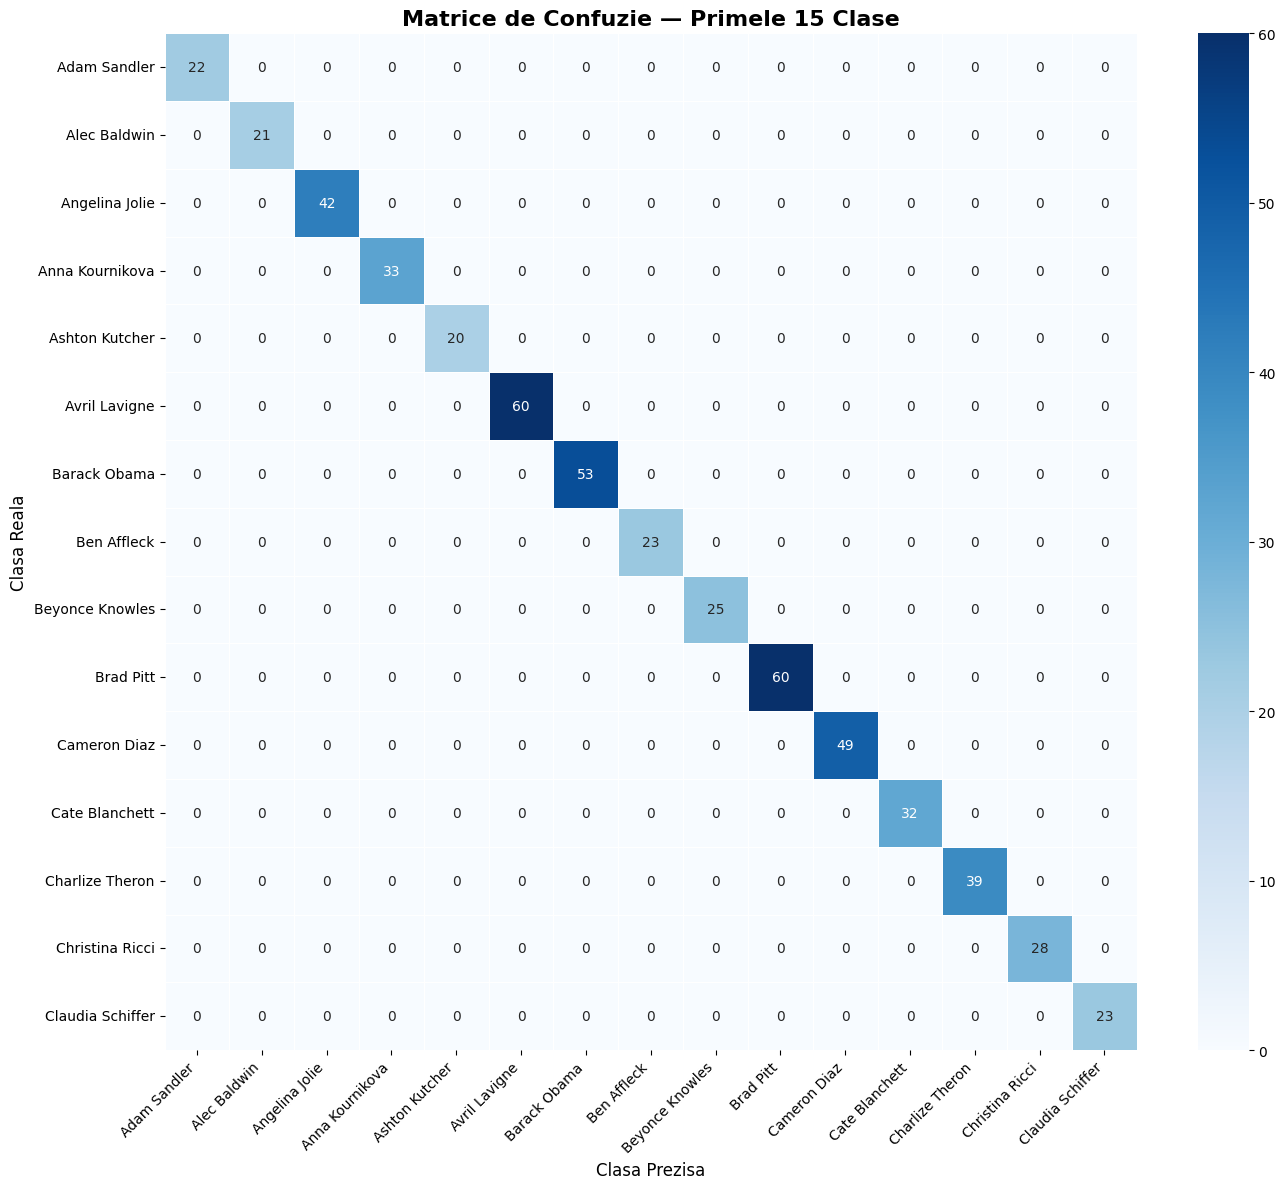

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

nr_clase_afisate=15
clase_selectate= list(range(nr_clase_afisate))

masca= np.isin(y_test, clase_selectate)
y_test_filtrat = y_test[masca]
predictii_filtrate = predictii[masca]

matrice = confusion_matrix(y_test_filtrat, predictii_filtrate, labels=clase_selectate)

nume_complete = []
for i in clase_selectate:
    nume_complete.append(encoder_etichete.classes_[i])

nume_prescurtate = []
for n in nume_complete:
    nume_prescurtate.append(n.split('_')[0])

plt.figure(figsize=(14, 12))
sns.heatmap(
    matrice,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=nume_prescurtate,
    yticklabels=nume_prescurtate,
    linewidths=0.5
)
plt.title('Matrice de Confuzie — Primele 15 Clase', fontsize=16, fontweight='bold')
plt.ylabel('Clasa Reala', fontsize=12)
plt.xlabel('Clasa Prezisa', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(models_path, 'confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# CELULA 8d — Comparatie SVM vs kNN vs Random Forest
# ============================================================

SVM: 99.06% | 11.32s
kNN: 99.06% | 1.11s
Random Forest: 98.62% | 171.39s


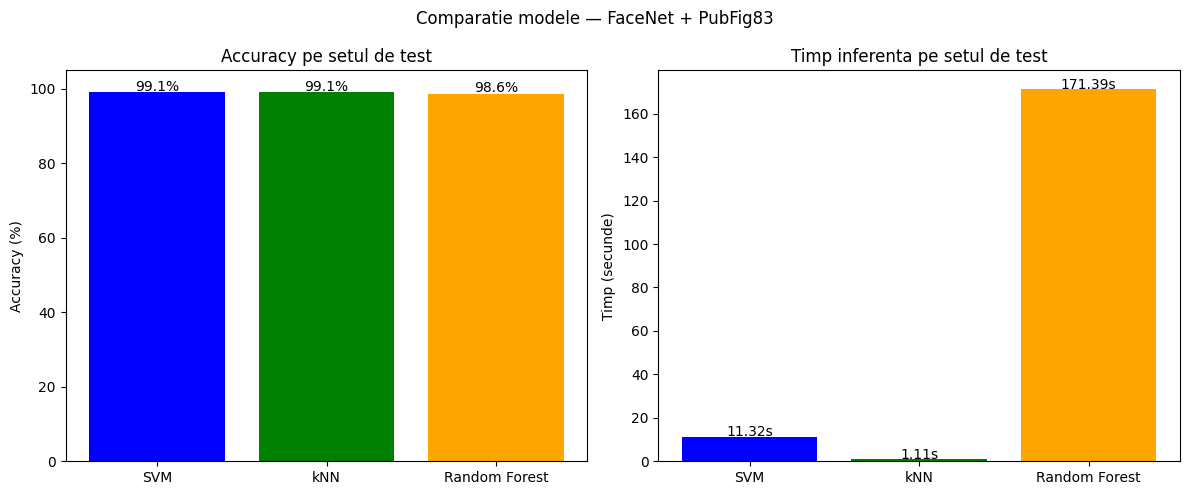

In [ ]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
import time

rezultate_comparatie = {}

t_start = time.time()
pred_svm = clasificator_svm.predict(X_test)
t_svm = time.time() - t_start
rezultate_comparatie['SVM'] = {
    'accuracy': accuracy_score(y_test, pred_svm),
    'timp': t_svm
}

t_start = time.time()
clasificator_knn = KNeighborsClassifier(n_neighbors=5, metric='cosine')
clasificator_knn.fit(X_train, y_train)
pred_knn = clasificator_knn.predict(X_test)
t_knn = time.time() - t_start
rezultate_comparatie['kNN'] = {
    'accuracy': accuracy_score(y_test, pred_knn),
    'timp': t_knn
}

t_start = time.time()
clasificator_rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
clasificator_rf.fit(X_train, y_train)
pred_rf = clasificator_rf.predict(X_test)
t_rf = time.time() - t_start
rezultate_comparatie['Random Forest'] = {
    'accuracy': accuracy_score(y_test, pred_rf),
    'timp': t_rf
}

for nume_model in rezultate_comparatie:
    val = rezultate_comparatie[nume_model]
    print(f"{nume_model}: {val['accuracy']*100:.2f}% | {val['timp']:.2f}s")

modele = list(rezultate_comparatie.keys())

accs = []
for m in modele:
    accs.append(rezultate_comparatie[m]['accuracy'] * 100)

timpi = []
for m in modele:
    timpi.append(rezultate_comparatie[m]['timp'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.bar(modele, accs, color=['blue', 'green', 'orange'])
ax1.set_title('Accuracy pe setul de test')
ax1.set_ylabel('Accuracy (%)')
ax1.set_ylim(0, 105)
for i in range(len(modele)):
    ax1.text(i, accs[i] + 0.5, f'{accs[i]:.1f}%', ha='center')

ax2.bar(modele, timpi, color=['blue', 'green', 'orange'])
ax2.set_title('Timp inferenta pe setul de test')
ax2.set_ylabel('Timp (secunde)')
for i in range(len(modele)):
    ax2.text(i, timpi[i] + 0.1, f'{timpi[i]:.2f}s', ha='center')

plt.suptitle('Comparatie modele — FaceNet + PubFig83')
plt.tight_layout()
plt.savefig(os.path.join(models_path, 'comparatie_modele.png'), dpi=150, bbox_inches='tight')
plt.show()



# ============================================================
# CELULA 9 — Salvare modele
# ============================================================

In [ ]:
final_models_path = os.path.join(drive_path, 'final_models')
os.makedirs(final_models_path, exist_ok=True)

SVM_PATH = os.path.join(final_models_path, 'svm_model.pkl')
LE_PATH  = os.path.join(final_models_path, 'label_encoder.pkl')

with open(SVM_PATH, 'wb') as f:
    pickle.dump(clasificator_svm, f)

with open(LE_PATH, 'wb') as f:
    pickle.dump(encoder_etichete, f)

print(f"SVM salvat: {SVM_PATH}")
print(f"LabelEncoder salvat: {LE_PATH}")
print(f"Clase invatate: {len(encoder_etichete.classes_)}")
print(f"Primele 10: {list(encoder_etichete.classes_[:10])}")

NameError: name 'os' is not defined

# ====================================================
# CELULA 10 — Descarcare modele pe calculator
# ====================================================

In [ ]:
from google.colab import files

files.download(SVM_PATH)
files.download(LE_PATH)

print("Download complet")

NameError: name 'SVM_PATH' is not defined